In [5]:
import requests
import base64

image_path = "1.Traffic sign main/40km/20ft/40_20_1.jpg"

with open(image_path, "rb") as image_file:
    image_base64 = base64.b64encode(image_file.read()).decode('utf-8')

api_key = "0dNYzkd71UBif63uZdnT"
url = f"https://detect.roboflow.com/traffic-sign-rw6j9/1?api_key={api_key}"

response = requests.post(url, data=image_base64, headers={"Content-Type": "application/x-www-form-urlencoded"})

print(response.json())


{'inference_id': '7f922049-614e-4a31-9fce-9aee96fd3333', 'time': 0.04624691500021072, 'image': {'width': 640, 'height': 640}, 'predictions': [{'x': 65.5, 'y': 234.5, 'width': 35.0, 'height': 45.0, 'confidence': 0.9322214126586914, 'class': '40km', 'class_id': 2, 'detection_id': 'be260e7c-ce3c-480e-b8f4-24124d757eb7'}]}


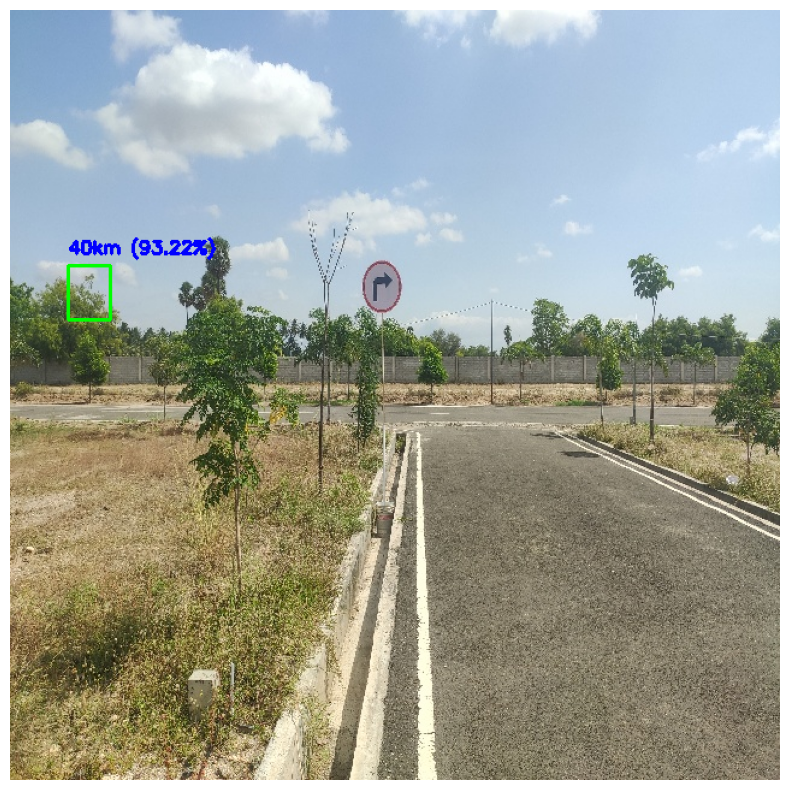

In [7]:
import cv2
import matplotlib.pyplot as plt

image_path = "1.Traffic sign main/Right_turn/20ft/Rt_20_9.jpg"
image = cv2.imread(image_path)

response = {
    'inference_id': '7f922049-614e-4a31-9fce-9aee96fd3333',
    'time': 0.04624691500021072,
    'image': {'width': 640, 'height': 640},
    'predictions': [
        {
            'x': 65.5, 'y': 234.5, 'width': 35.0, 'height': 45.0,
            'confidence': 0.9322214126586914, 'class': '40km',
            'class_id': 2, 'detection_id': 'be260e7c-ce3c-480e-b8f4-24124d757eb7'
        }
    ]
}

for prediction in response['predictions']:
    x = int(prediction['x'] - prediction['width'] / 2)
    y = int(prediction['y'] - prediction['height'] / 2)
    width = int(prediction['width'])
    height = int(prediction['height'])
    
    cv2.rectangle(image, (x, y), (x + width, y + height), (0, 255, 0), 2)
    
    label = f"{prediction['class']} ({prediction['confidence']*100:.2f}%)"
    cv2.putText(image, label, (x, y - 10), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (255, 0, 0), 2)

image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(10, 10))
plt.imshow(image)
plt.axis('off') 
plt.show()


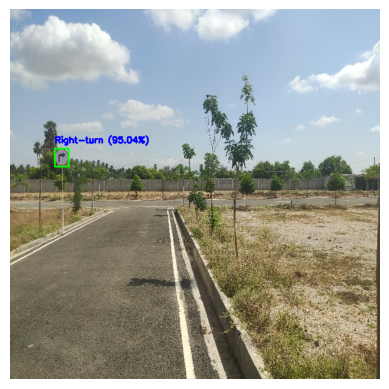

In [1]:
import requests
import base64
import tensorflow as tf
import numpy as np
import cv2

def roboflow_predict(image_path, api_key, model_endpoint):
    with open(image_path, "rb") as image_file:
        image_base64 = base64.b64encode(image_file.read()).decode('utf-8')

    url = f"https://detect.roboflow.com/{model_endpoint}?api_key={api_key}"
    
    response = requests.post(url, data=image_base64, headers={"Content-Type": "application/x-www-form-urlencoded"})
    return response.json()

api_key = "0dNYzkd71UBif63uZdnT"
model_endpoint = "traffic-sign-rw6j9/1"

image_path = "1.Traffic sign main/Right_turn/30ft/Rt_30_1.jpg"

response = roboflow_predict(image_path, api_key, model_endpoint)

image = cv2.imread(image_path)
image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

image_tensor = tf.convert_to_tensor(image_rgb, dtype=tf.float32)
image_tensor = tf.expand_dims(image_tensor, axis=0)  

for prediction in response['predictions']:
    x = int(prediction['x'] - prediction['width'] / 2)
    y = int(prediction['y'] - prediction['height'] / 2)
    width = int(prediction['width'])
    height = int(prediction['height'])
    
    cv2.rectangle(image, (x, y), (x + width, y + height), (0, 255, 0), 2)
    
    label = f"{prediction['class']} ({prediction['confidence']*100:.2f}%)"
    cv2.putText(image, label, (x, y - 10), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (255, 0, 0), 2)

image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

import matplotlib.pyplot as plt
plt.imshow(image_rgb)
plt.axis('off')
plt.show()


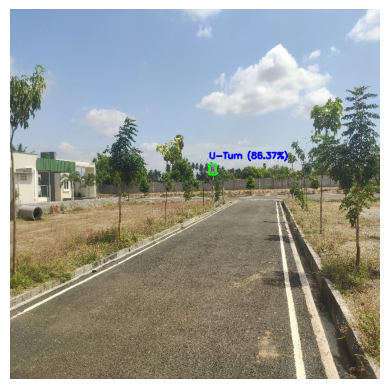

In [2]:
import requests
import base64
import torch
import numpy as np
import cv2
from torchvision import transforms
import matplotlib.pyplot as plt

def roboflow_predict(image_path, api_key, model_endpoint):
    with open(image_path, "rb") as image_file:
        image_base64 = base64.b64encode(image_file.read()).decode('utf-8')

    url = f"https://detect.roboflow.com/{model_endpoint}?api_key={api_key}"
    
    response = requests.post(url, data=image_base64, headers={"Content-Type": "application/x-www-form-urlencoded"})
    return response.json()

api_key = "0dNYzkd71UBif63uZdnT"
model_endpoint = "traffic-sign-rw6j9/1"

image_path = "1.Traffic sign main/U_turn/50ft/Ut_50_2.jpg"

response = roboflow_predict(image_path, api_key, model_endpoint)

image = cv2.imread(image_path)

image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

transform = transforms.Compose([
    transforms.ToPILImage(),
    transforms.ToTensor()
])

image_tensor = transform(image_rgb)

image_tensor = image_tensor.unsqueeze(0)

for prediction in response['predictions']:
    x = int(prediction['x'] - prediction['width'] / 2)
    y = int(prediction['y'] - prediction['height'] / 2)
    width = int(prediction['width'])
    height = int(prediction['height'])
    
    cv2.rectangle(image, (x, y), (x + width, y + height), (0, 255, 0), 2)
    
    label = f"{prediction['class']} ({prediction['confidence']*100:.2f}%)"
    cv2.putText(image, label, (x, y - 10), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (255, 0, 0), 2)

image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

plt.imshow(image_rgb)
plt.axis('off')
plt.show()
